# Early Hospital Readmission in Patients with Diabetes: pandas Analysis

Reproduction in Python (pandas, NumPy, matplotlib, seaborn) of the SQL analysis in this repository.
Every result is checked against the SQL version (cohort of 69,990 patients; early readmission 8.98%).

**Data:** UCI Machine Learning Repository, *Diabetes 130-US Hospitals for Years 1999–2008*.
**Reference:** Strack et al. (2014), https://doi.org/10.1155/2014/781670

**Contents**
1. Setup
2. Load and validate the data
3. Binary readmission variable
4. Lookup tables
5. Analysis cohort
6. Analysis (Q1–Q10)
7. Charts

**Reading the results:** `readmission_rate` is a proportion (0–1) with 4 decimals, as in SQL.
Percentages are used only in charts. All comparisons are descriptive and unadjusted.
Groups under 100 patients are not interpreted.

## 1. Setup

In [1]:
# 1.1 Libraries
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1.2 Environment (for reproducibility)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)

pandas: 3.1.0
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2


In [3]:
# 1.3 Paths: relative to the project root, so the notebook runs from the root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
REF_DIR = ROOT / "data" / "reference"
PLOTS_DIR = ROOT / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

## 2. Load and validate the data
`na_values="?"` turns `?` into a missing value. `keep_default_na=False` stops pandas from also treating the
text `"None"` as missing: in `A1Cresult`, `"None"` means *test not measured*, a real category
(same behaviour as `nullstr='?'` in DuckDB).

In [4]:
# 2.1 Load the encounters
diabetes_encounters = pd.read_csv(
    RAW_DIR / "diabetic_data.csv",
    na_values="?",
    keep_default_na=False,
    low_memory=False,  # infer types from the whole file (avoids a mixed-type warning in payer_code)
)
diabetes_encounters.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [5]:
# 2.2 Column names, data types and non-null counts
diabetes_encounters.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [6]:
# 2.3 Size and uniqueness of encounter_id (both counts must be equal)
print("Total columns:", diabetes_encounters.shape[1])
print("Total rows:", len(diabetes_encounters))
print("Unique encounter IDs:", diabetes_encounters["encounter_id"].nunique())

Total columns: 50
Total rows: 101766
Unique encounter IDs: 101766


In [7]:
# 2.4 First 10 rows, to confirm the file loaded correctly
diabetes_encounters.head(10)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),NaN,2,1,2,3,...,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),NaN,3,1,2,4,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),NaN,1,1,7,5,...,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),NaN,2,1,4,13,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),NaN,3,3,4,12,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [8]:
# 2.5 Missing values per column (%), equivalent to null_percentage in DuckDB's SUMMARIZE
null_percentage = (diabetes_encounters.isna().mean() * 100).round(2)
null_percentage[null_percentage > 0].sort_values(ascending=False)

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

In [9]:
# 2.6 Numeric profile
diabetes_encounters.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


## 3. Binary readmission variable
`early_readmission = 1` only when the patient was readmitted within 30 days (`<30`), the classic hospital convention
(Strack et al., 2014). Both `>30` and `NO` are coded 0.

In [10]:
# 3.1 Create the variable
diabetes_encounters["early_readmission"] = np.where(diabetes_encounters["readmitted"] == "<30", 1, 0)
diabetes_encounters["early_readmission"].value_counts()

early_readmission
0    90409
1    11357
Name: count, dtype: int64

In [11]:
# 3.2 Check: only '<30' must map to 1
diabetes_encounters.groupby(["readmitted", "early_readmission"]).size().reset_index(name="total_rows")

,readmitted,early_readmission,total_rows
0,<30,1,11357
1,>30,0,35545
2,NO,0,54864


## 4. Lookup tables
`IDs_mapping.csv` (included with the original dataset) stacks three lookup tables in one file.
They were split manually into three CSV files so they can be joined.
Each `description` column is renamed when loaded, so later joins do not depend on automatic suffixes (`_x`, `_y`),
and leading spaces (e.g. `" Physician Referral"`) are removed.

In [12]:
# 4.1 Admission type
admission_type = pd.read_csv(REF_DIR / "admission_type.csv").rename(columns={"description": "admission_type_desc"})
admission_type["admission_type_desc"] = admission_type["admission_type_desc"].str.strip()

# 4.2 Admission source
admission_source = pd.read_csv(REF_DIR / "admission_source.csv").rename(columns={"description": "admission_source_desc"})
admission_source["admission_source_desc"] = admission_source["admission_source_desc"].str.strip()

# 4.3 Discharge disposition
discharge_disposition = pd.read_csv(REF_DIR / "discharge_disposition.csv").rename(columns={"description": "discharge_destination"})
discharge_disposition["discharge_destination"] = discharge_disposition["discharge_destination"].str.strip()

print("Admission type:", admission_type.shape)
print("Admission source:", admission_source.shape)
print("Discharge disposition:", discharge_disposition.shape)

Admission type: (8, 2)
Admission source: (25, 2)
Discharge disposition: (30, 2)


In [13]:
# 4.4 Check the lookup tables
admission_type.head(6)

,admission_type_id,admission_type_desc
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN


In [14]:
admission_source.head(6)

,admission_source_id,admission_source_desc
0,1,Physician Referral
1,2,Clinic Referral
2,3,HMO Referral
3,4,Transfer from a hospital
4,5,Transfer from a Skilled Nursing Facility (SNF)
5,6,Transfer from another health care facility


In [15]:
discharge_disposition.head(6)

,discharge_disposition_id,discharge_destination
0,1,Discharged to home
1,2,Discharged/transferred to another short term h...
2,3,Discharged/transferred to SNF
3,4,Discharged/transferred to ICF
4,5,Discharged/transferred to another type of inpa...
5,6,Discharged/transferred to home with home healt...


## 5. Analysis cohort
1. Exclude encounters ending in death or hospice discharge (`discharge_disposition_id` 11, 13, 14, 19, 20, 21):
   these patients cannot be readmitted and would underestimate the readmission rate.
2. Keep one encounter per patient (the first eligible one by `encounter_id`), so a patient with many encounters
   does not weigh more than once.

*Limitation:* the dataset has no dates, so `encounter_id` is only an approximation of the temporal order.

From here on, `analysis_cohort` is **not modified**: each question adds its own columns with `.assign()`.

In [16]:
# 5.1 Exclude death and hospice discharges
# .copy(): this filtered subset is modified in the next step, and the original table must stay intact
analysis_cohort = diabetes_encounters[~diabetes_encounters["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])].copy()

print("Original rows:", len(diabetes_encounters))
print("Eligible rows:", len(analysis_cohort))
print("Death/hospice codes left:", analysis_cohort["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21]).sum())

Original rows: 101766
Eligible rows: 99343
Death/hospice codes left: 0


In [17]:
# 5.2 Number each patient's encounters in order of encounter_id
# Equivalent to SQL: ROW_NUMBER() OVER (PARTITION BY patient_nbr ORDER BY encounter_id)
analysis_cohort = analysis_cohort.sort_values("encounter_id")
analysis_cohort["enc_order"] = analysis_cohort.groupby("patient_nbr")["encounter_id"].rank(method="first").astype(int)

analysis_cohort[["patient_nbr", "encounter_id", "enc_order"]].head()

,patient_nbr,encounter_id,enc_order
8,48330783,12522,1
9,63555939,15738,1
4,42519267,16680,1
10,89869032,28236,1
5,82637451,35754,1


In [18]:
# 5.3 Keep the first encounter per patient and drop the helper column (SQL: EXCLUDE (enc_order))
analysis_cohort = analysis_cohort.loc[analysis_cohort["enc_order"] == 1].drop(columns="enc_order").reset_index(drop=True)

# One-step alternative with the same result:
# analysis_cohort = analysis_cohort.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")

# Check: one row per patient (both counts must be equal)
print("Total rows:", len(analysis_cohort))
print("Unique patients:", analysis_cohort["patient_nbr"].nunique())

Total rows: 69990
Unique patients: 69990


## 6. Analysis
### Q1. How big is the cohort and how are readmissions distributed?

In [19]:
# 1.1 Cohort flow: from the raw data to the final cohort
excluded_death_hospice = diabetes_encounters["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21]).sum()

print("Raw encounters:", len(diabetes_encounters))
print("Raw unique patients:", diabetes_encounters["patient_nbr"].nunique())
print("Excluded death/hospice:", excluded_death_hospice)
print("Final cohort patients:", len(analysis_cohort))

Raw encounters: 101766
Raw unique patients: 71518
Excluded death/hospice: 2423
Final cohort patients: 69990


In [20]:
# 1.2 Readmission distribution (count and percentage)
readmission_distribution = analysis_cohort.groupby("readmitted").size().reset_index(name="total_patients")
readmission_distribution["pct_patients"] = (
    readmission_distribution["total_patients"] * 100 / readmission_distribution["total_patients"].sum()
).round(2)

readmission_distribution.sort_values("total_patients", ascending=False)

,readmitted,total_patients,pct_patients
2,NO,41479,59.26
1,>30,22226,31.76
0,<30,6285,8.98


**Finding Q1:** 101,766 encounters (71,518 patients) → 69,990 patients after excluding death/hospice discharges
and keeping one encounter per patient. Early readmission (<30 days): 8.98% (n = 6,285); >30 days: 31.76%;
no readmission: 59.26%.

### Q2. Does early readmission change with age?

In [21]:
age_readmission = analysis_cohort.groupby("age").agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

age_readmission.sort_values("age")

,age,total_patients,readmission_rate
0,[0-10),153,0.0196
1,[10-20),534,0.0487
2,[20-30),1121,0.0740
3,[30-40),2692,0.0698
4,[40-50),6828,0.0741
5,[50-60),12351,0.0712
6,[60-70),15689,0.0902
7,[70-80),17751,0.1024
8,[80-90),11110,0.1079
9,[90-100),1761,0.0954


**Finding Q2:** readmission rises with age: ~7% between ages 30 and 60 vs 10.2–10.8% at ages 70–90
(the 70–80 and 80–90 groups are not distinguishable). Groups under 600 patients (ages 0–20) are not interpreted.

### Q3. Are there differences by sex or race?
Race and sex are used as recorded in the dataset. Missing race, the heterogeneous `Other` race category and
`Unknown/Invalid` sex are left out of the comparison; groups with fewer than 100 patients are not shown.

In [22]:
# Q3. Readmission by sex and race
sex_race = analysis_cohort.loc[
    analysis_cohort["gender"].notna() & (analysis_cohort["gender"] != "Unknown/Invalid")
    & analysis_cohort["race"].notna() & (analysis_cohort["race"] != "Other")
]

sex_race_readmission = sex_race.groupby(["gender", "race"]).agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

# Minimum group size (SQL: HAVING COUNT(*) >= 100)
sex_race_readmission = sex_race_readmission.loc[sex_race_readmission["total_patients"] >= 100]

sex_race_readmission.sort_values("readmission_rate", ascending=False)

,gender,race,total_patients,readmission_rate
5,Male,Asian,241,0.1079
2,Female,Caucasian,26959,0.0929
6,Male,Caucasian,25346,0.0908
7,Male,Hispanic,694,0.0893
0,Female,AfricanAmerican,7680,0.0882
4,Male,AfricanAmerican,4947,0.0845
3,Female,Hispanic,807,0.0743
1,Female,Asian,247,0.0607


In [23]:
# 3.1 Patients included in and left out of this comparison
# Categories as recorded in the dataset; only these are compared in Q3
compared_sexes = ["Male", "Female"]
compared_races = ["Asian", "Caucasian", "Hispanic", "AfricanAmerican"]

in_comparison = analysis_cohort["gender"].isin(compared_sexes) & analysis_cohort["race"].isin(compared_races)
comparison_status = analysis_cohort.assign(group_status=np.where(in_comparison, "Included", "Excluded"))

included_excluded = comparison_status.groupby("group_status").size().reset_index(name="total_patients")
included_excluded["percentage"] = (
    included_excluded["total_patients"] * 100 / included_excluded["total_patients"].sum()
).round(2)

included_excluded

,group_status,total_patients,percentage
0,Excluded,3069,4.38
1,Included,66921,95.62


**Finding Q3:** no clear differences by sex or race (6.07%–10.79% vs 8.98% overall). The largest groups are
practically identical (Caucasian women 9.29%, n = 26,959; Caucasian men 9.08%, n = 25,346). Hispanic and Asian
groups are small (n = 241–807); 4.38% of the cohort is left out of this comparison. Unadjusted for age or severity.

### Q4. Is a longer stay associated with more readmissions?

In [24]:
# 4.1 Average length of stay by readmission category
length_of_stay = analysis_cohort.groupby("readmitted").agg(
    total_patients=("time_in_hospital", "size"),
    avg_days_in_hospital=("time_in_hospital", "mean"),
).reset_index().round(4)

length_of_stay.sort_values("avg_days_in_hospital", ascending=False)

,readmitted,total_patients,avg_days_in_hospital
0,<30,6285,4.7947
1,>30,22226,4.4198
2,NO,41479,4.1158


In [25]:
# 4.2 Readmission rate by length-of-stay range (the dataset only includes stays of 1–14 days)
stay_conditions = [
    analysis_cohort["time_in_hospital"].between(1, 3),
    analysis_cohort["time_in_hospital"].between(4, 7),
    analysis_cohort["time_in_hospital"] >= 8,
]
stay_labels = ["1-3 days", "4-7 days", "8-14 days"]

stay = analysis_cohort.assign(stay_range=np.select(stay_conditions, stay_labels, default="Others/Error"))

stay_readmission = stay.groupby("stay_range").agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

stay_readmission.sort_values("stay_range")

,stay_range,total_patients,readmission_rate
0,1-3 days,35146,0.0753
1,4-7 days,25075,0.0991
2,8-14 days,9769,0.1179


**Finding Q4:** 7.53% (1–3 days, n = 35,146), 9.91% (4–7 days, n = 25,075) and 11.79% (8–14 days, n = 9,769).
Readmitted patients stayed 4.8 days on average vs 4.1. An association that likely reflects clinical severity.

### Q5. Does patient complexity matter? Polypharmacy and multimorbidity
Two dimensions of clinical complexity (number of medications and number of diagnoses) are crossed.

In [26]:
# pd.cut() builds ranges from continuous values (Q4 uses np.select for the same purpose).
# bins=[0, 10, 20, inf] creates the intervals (0, 10], (10, 20] and (20, inf)
medication_range = pd.cut(analysis_cohort["num_medications"],
                          bins=[0, 10, 20, np.inf],
                          labels=["1-10 low", "11-20 moderate", "21+ severe"])

diagnosis_range = pd.cut(analysis_cohort["number_diagnoses"],
                         bins=[0, 4, 8, np.inf],
                         labels=["1-4 low", "5-8 moderate", "9+ severe"])

complexity = analysis_cohort.assign(medication_range=medication_range, diagnosis_range=diagnosis_range)

# observed=True: keep only the combinations that exist (needed when grouping pd.cut categories)
complexity_readmission = complexity.groupby(["medication_range", "diagnosis_range"], observed=True).agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

complexity_readmission.sort_values("readmission_rate", ascending=False)

,medication_range,diagnosis_range,total_patients,readmission_rate
8,21+ severe,9+ severe,9172,0.1107
7,21+ severe,5-8 moderate,5410,0.1018
5,11-20 moderate,9+ severe,16339,0.0996
4,11-20 moderate,5-8 moderate,15762,0.0897
2,1-10 low,9+ severe,5281,0.0860
1,1-10 low,5-8 moderate,10153,0.0725
3,11-20 moderate,1-4 low,2945,0.0696
6,21+ severe,1-4 low,863,0.0579
0,1-10 low,1-4 low,4065,0.0573


**Finding Q5:** readmission rises with clinical complexity, from 5.73% (1–10 medications and 1–4 diagnoses,
n = 4,065) to 11.07% (21+ medications and 9+ diagnoses, n = 9,172). These indicators overlap with length of stay
(a shared severity signal). The 21+ medications / 1–4 diagnoses cell (n = 863) is not interpreted.

### Q6. Where is the risk, according to how the patient arrived and left?
Hospital circuit = admission type + admission source + discharge destination. Records with *missing data* IDs
are excluded; circuits with fewer than 500 patients are not shown.

In [27]:
hospital_circuit = (
    analysis_cohort
    .merge(admission_type, on="admission_type_id", how="inner")
    .merge(admission_source, on="admission_source_id", how="inner")
    .merge(discharge_disposition, on="discharge_disposition_id", how="inner")
)

# Exclude 'missing data' IDs in each dimension
hospital_circuit = hospital_circuit[
    ~hospital_circuit["admission_type_id"].isin([5, 6, 8])
    & ~hospital_circuit["admission_source_id"].isin([9, 15, 17, 20, 21])
    & ~hospital_circuit["discharge_disposition_id"].isin([18, 25, 26])
]

circuit_readmission = hospital_circuit.groupby(
    ["admission_type_desc", "admission_source_desc", "discharge_destination"]
).agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

circuit_readmission = circuit_readmission[circuit_readmission["total_patients"] >= 500]

circuit_readmission.sort_values("readmission_rate", ascending=False)

,admission_type_desc,admission_source_desc,discharge_destination,total_patients,readmission_rate
79,Emergency,Emergency Room,Discharged/transferred to another rehab fac in...,667,0.2984
180,Urgent,Physician Referral,Discharged/transferred to SNF,524,0.1679
75,Emergency,Emergency Room,Discharged/transferred to SNF,4059,0.1402
21,Elective,Physician Referral,Discharged/transferred to SNF,1022,0.1321
165,Urgent,Emergency Room,Discharged/transferred to SNF,651,0.1060
83,Emergency,Emergency Room,Discharged/transferred to home with home healt...,3635,0.1010
80,Emergency,Emergency Room,Discharged/transferred to another short term h...,753,0.0930
187,Urgent,Physician Referral,Discharged/transferred to home with home healt...,729,0.0919
178,Urgent,Physician Referral,Discharged to home,4856,0.0762
163,Urgent,Emergency Room,Discharged to home,2347,0.0733


In [28]:
# 6.1 Validation: discharge destination alone, without crossing other dimensions
discharge = analysis_cohort.merge(discharge_disposition, on="discharge_disposition_id", how="inner")

discharge_readmission = discharge.groupby("discharge_destination").agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

discharge_readmission = discharge_readmission[discharge_readmission["total_patients"] >= 100]

discharge_readmission.sort_values("readmission_rate", ascending=False)

,discharge_destination,total_patients,readmission_rate
7,Discharged/transferred to another rehab fac in...,1411,0.2636
9,Discharged/transferred to another type of inpa...,913,0.2059
8,Discharged/transferred to another short term h...,1541,0.1376
3,Discharged/transferred to SNF,8790,0.1342
2,Discharged/transferred to ICF,542,0.1033
16,Left AMA,409,0.0954
11,Discharged/transferred to home with home healt...,8291,0.0954
1,Discharged to home,44322,0.0695
18,Not Mapped,778,0.0617
5,Discharged/transferred to a long term care hos...,260,0.0308


**Finding Q6:** discharge destination is strongly associated with readmission: 26.36% after discharge to a
rehabilitation facility (n = 1,411) vs 6.95% after discharge home (n = 44,322). The highest-risk circuit was
emergency admission through the ER followed by rehabilitation: 29.8% (n = 667). Likely confounded by severity.

### Q7. Is measuring HbA1c associated with readmission?
HbA1c reflects average glycemic control over the previous ~3 months. The original study (Strack et al., 2014)
asked whether measuring it during the stay was associated with fewer early readmissions. `"None"` means the test was not measured.

In [29]:
hba1c_readmission = analysis_cohort.groupby("A1Cresult").agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

hba1c_readmission.sort_values("readmission_rate", ascending=False)

,A1Cresult,total_patients,readmission_rate
2,None,57144,0.0911
3,Norm,3741,0.0863
0,>7,2866,0.0862
1,>8,6239,0.0816


In [30]:
# 7.1 Measured vs not measured
hba1c = analysis_cohort.assign(
    hba1c=np.where(analysis_cohort["A1Cresult"] == "None", "Not measured", "Measured")
)

hba1c_measured = hba1c.groupby("hba1c").agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)
hba1c_measured["pct_patients"] = (hba1c_measured["total_patients"] * 100 / len(analysis_cohort)).round(2)

hba1c_measured.sort_values("readmission_rate")

,hba1c,total_patients,readmission_rate,pct_patients
0,Measured,12846,0.0840,18.35
1,Not measured,57144,0.0911,81.65


**Finding Q7:** HbA1c was measured in 18.35% of patients (12,846 of 69,990), consistent with the original study.
Readmission was 8.40% when measured vs 9.11% when not: a small, unadjusted difference. The original study found the
relationship depends on the primary diagnosis.

### Q8. Are treatment changes associated with readmission?
Only combinations that exist in the data appear: an insulin change implies `Ch`, and no diabetes medication implies
no insulin and no change.

In [31]:
treatment = analysis_cohort.loc[
    analysis_cohort["change"].notna() & analysis_cohort["diabetesMed"].notna() & analysis_cohort["insulin"].notna()
]

treatment_readmission = treatment.groupby(["change", "diabetesMed", "insulin"]).agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)
treatment_readmission["pct_patients"] = (treatment_readmission["total_patients"] * 100 / len(analysis_cohort)).round(2)

treatment_readmission = treatment_readmission[treatment_readmission["total_patients"] >= 100]

treatment_readmission.sort_values("readmission_rate", ascending=False)

,change,diabetesMed,insulin,total_patients,readmission_rate,pct_patients
0,Ch,Yes,Down,7324,0.1054,10.46
3,Ch,Yes,Up,6777,0.0984,9.68
6,No,Yes,Steady,10925,0.0946,15.61
5,No,Yes,No,10882,0.0934,15.55
2,Ch,Yes,Steady,10696,0.0906,15.28
1,Ch,Yes,No,6700,0.0843,9.57
4,No,No,No,16686,0.0756,23.84


In [32]:
# 8.1 Any medication change, whole cohort
change_readmission = analysis_cohort.groupby("change").agg(
    total_patients=("early_readmission", "size"),
    early_readmissions=("early_readmission", "sum"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

change_readmission

,change,total_patients,early_readmissions,readmission_rate
0,Ch,31497,2973,0.0944
1,No,38493,3312,0.0860


In [33]:
# 8.2 Same comparison among patients taking diabetes medication only
# Needed because the 'No' group in 8.1 includes patients without any diabetes medication
treated = analysis_cohort.loc[analysis_cohort["diabetesMed"] == "Yes"]

treated_change_readmission = treated.groupby("change").agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

treated_change_readmission

,change,total_patients,readmission_rate
0,Ch,31497,0.0944
1,No,21807,0.0940


**Finding Q8:** patients without diabetes medication had the lowest readmission (7.56%, n = 16,686). Among treated
patients, insulin dose changes were associated with higher rates (decreased 10.54%, increased 9.84%) than steady or no
insulin (8.43%–9.46%). Any medication change on its own showed no difference among treated patients (~9.4% both).
Likely confounding by indication.

### Q9. Which principal diagnoses concentrate the most cases and readmissions?
`diag_1` (ICD-9) is converted to a number before comparing ranges, because text comparison would misplace short codes
such as `'41'` or `'53'`. Groups follow the ICD-9 chapters used in the original study.

In [34]:
# Numeric version of diag_1: codes such as 'V57' or 'E888' become NaN (SQL: TRY_CAST(diag_1 AS DOUBLE))
code_num = pd.to_numeric(analysis_cohort["diag_1"], errors="coerce")
code_floor = np.floor(code_num)

# Half-open intervals [low, high) capture every decimal without listing .99
diagnosis_conditions = [
    analysis_cohort["diag_1"].isna(),
    analysis_cohort["diag_1"].str.startswith(("V", "E"), na=False),
    (code_num >= 250) & (code_num < 251),
    ((code_num >= 390) & (code_num < 460)) | (code_floor == 785),
    ((code_num >= 460) & (code_num < 520)) | (code_floor == 786),
    ((code_num >= 520) & (code_num < 580)) | (code_floor == 787),
    ((code_num >= 580) & (code_num < 630)) | (code_floor == 788),
    (code_num >= 140) & (code_num < 240),
    (code_num >= 710) & (code_num < 740),
    (code_num >= 800) & (code_num < 1000),
]
diagnosis_labels = [
    "Unknown/missing", "Other (V/E codes)", "Diabetes", "Circulatory", "Respiratory",
    "Digestive", "Genitourinary", "Neoplasms", "Musculoskeletal", "Injury/poisoning",
]

diagnosis = analysis_cohort.assign(
    diagnostic_group=np.select(diagnosis_conditions, diagnosis_labels, default="Other")
)

diagnosis_readmission = diagnosis.groupby("diagnostic_group").agg(
    total_patients=("early_readmission", "size"),
    readmissions=("early_readmission", "sum"),
    readmission_rate=("early_readmission", "mean"),
).reset_index()

diagnosis_readmission["pct_of_patients"] = (
    diagnosis_readmission["total_patients"] * 100 / diagnosis_readmission["total_patients"].sum()).round(2)
diagnosis_readmission["pct_of_readmissions"] = (
    diagnosis_readmission["readmissions"] * 100 / diagnosis_readmission["readmissions"].sum()).round(2)
diagnosis_readmission["readmission_rate"] = diagnosis_readmission["readmission_rate"].round(4)

# Ties share the same position (SQL: RANK())
diagnosis_readmission["risk_rank"] = diagnosis_readmission["readmission_rate"].rank(method="min", ascending=False).astype(int)

diagnosis_readmission[["diagnostic_group", "total_patients", "pct_of_patients",
                       "pct_of_readmissions", "readmission_rate", "risk_rank"]].sort_values("risk_rank")

,diagnostic_group,total_patients,pct_of_patients,pct_of_readmissions,readmission_rate,risk_rank
10,Unknown/missing,10,0.01,0.03,0.2000,1
8,Other (V/E codes),919,1.31,1.97,0.1349,2
4,Injury/poisoning,4696,6.71,8.07,0.1080,3
0,Circulatory,21390,30.56,32.94,0.0968,4
1,Diabetes,5748,8.21,8.34,0.0912,5
6,Neoplasms,2538,3.63,3.66,0.0906,6
3,Genitourinary,3441,4.92,4.92,0.0898,7
7,Other,11205,16.01,15.35,0.0861,8
5,Musculoskeletal,4064,5.81,5.43,0.0839,9
2,Digestive,6488,9.27,8.27,0.0801,10


**Finding Q9:** circulatory diseases were the most frequent principal diagnosis (30.6% of patients) and accounted for
a third of readmissions (32.9%), with a rate close to the overall one (9.68%). Injury/poisoning had a higher rate
(10.80%, n = 4,696) and respiratory diseases the lowest (7.30%, n = 9,491). Only 8.2% of patients had diabetes as
principal diagnosis. Groups under 100 patients (missing diagnosis, n = 10) are not interpreted, even if they rank first.

### Q10. Which specialties deviate from the hospital average?
Specialties with ≥ 200 patients. The baseline is the **global** readmission rate (all patients in the cohort),
not an average of specialty rates. Missing specialty is reported as `Unknown`.

In [35]:
# A single value, used as the baseline for every specialty
global_rate = analysis_cohort["early_readmission"].mean()

specialty = analysis_cohort.assign(medical_specialty=analysis_cohort["medical_specialty"].fillna("Unknown"))

specialty_readmission = specialty.groupby("medical_specialty").agg(
    total_patients=("early_readmission", "size"),
    readmission_rate=("early_readmission", "mean"),
).reset_index().round(4)

specialty_readmission = specialty_readmission[specialty_readmission["total_patients"] >= 200]
specialty_readmission["diff_vs_global"] = (specialty_readmission["readmission_rate"] - global_rate).round(4)
specialty_readmission["risk_rank"] = specialty_readmission["readmission_rate"].rank(method="min", ascending=False).astype(int)

print(f"Global rate: {global_rate:.4f}")
specialty_readmission.sort_values("risk_rank")

Global rate: 0.0898


,medical_specialty,total_patients,readmission_rate,diff_vs_global,risk_rank
25,Oncology,205,0.1805,0.0907,1
67,Surgery-Vascular,359,0.1198,0.0300,2
45,Psychiatry,613,0.1109,0.0211,3
19,Nephrology,797,0.1104,0.0206,4
12,Gastroenterology,384,0.1068,0.0170,5
27,Orthopedics,1128,0.0993,0.0095,6
18,InternalMedicine,10641,0.0976,0.0078,7
11,Family/GeneralPractice,4978,0.0974,0.0076,8
49,Pulmonology,637,0.0942,0.0044,9
69,Unknown,33654,0.0924,0.0026,10


In [36]:
# 10.1 Patients with no recorded specialty
pct_unknown = round(analysis_cohort["medical_specialty"].isna().mean() * 100, 1)
print(f"Patients with no recorded specialty: {pct_unknown}%")

Patients with no recorded specialty: 48.1%


**Finding Q10:** among specialties with 200+ patients, oncology had about twice the global rate (18.05% vs 8.98%,
n = 205) and obstetrics and gynecology the lowest (3.71%, n = 593). The other specialties are within the margin of
error of the global rate. Specialty is missing for 48.1% of patients, so results describe only those with a recorded specialty.

## 7. Charts
Rates are shown as percentages. The dashed line marks the cohort-wide early readmission rate (8.98%).
Every chart is also saved as a PNG file in `plots/`.

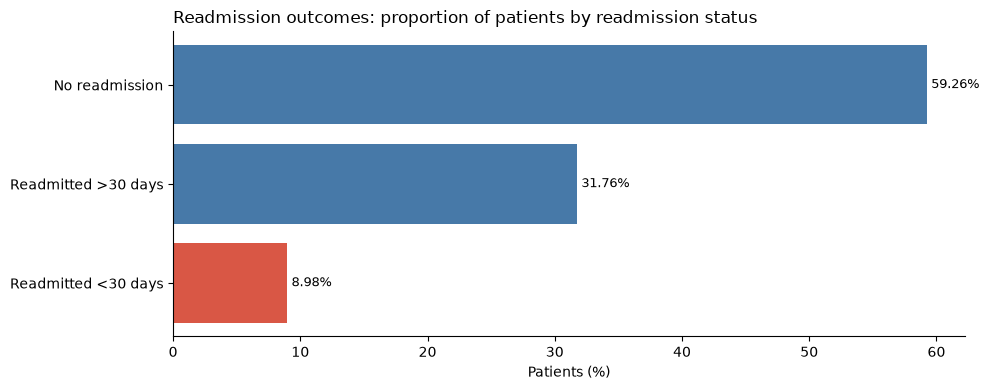

In [37]:
# 7.1 Readmission outcomes
outcome_labels = {"NO": "No readmission", ">30": "Readmitted >30 days", "<30": "Readmitted <30 days"}
outcomes_plot = readmission_distribution.sort_values("pct_patients").assign(
    readmitted=lambda df: df["readmitted"].replace(outcome_labels)
)

# Highlight early readmission (the smallest group)
colors = ["#d95745" if val == outcomes_plot["pct_patients"].min() else "#4779a8"
          for val in outcomes_plot["pct_patients"]]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(outcomes_plot["readmitted"], outcomes_plot["pct_patients"], color=colors)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)

ax.set_xlabel("Patients (%)")
ax.set_title("Readmission outcomes: proportion of patients by readmission status", loc="left")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "01_readmission_outcomes.png", dpi=150, bbox_inches="tight")
plt.show()

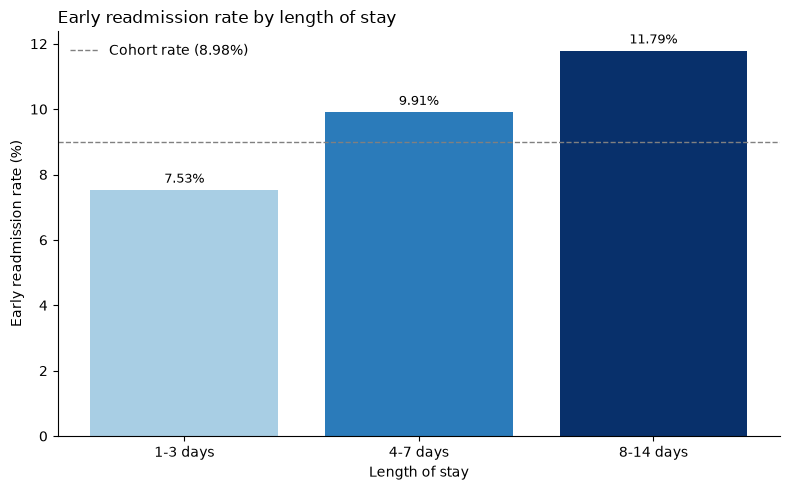

In [38]:
# 7.2 Early readmission by length of stay
stay_plot = stay_readmission.sort_values("stay_range").assign(
    readmission_pct=lambda df: df["readmission_rate"] * 100
)

# Shades of blue proportional to the rate
norm = plt.Normalize(stay_plot["readmission_pct"].min() * 0.7, stay_plot["readmission_pct"].max())
colors = plt.cm.Blues(norm(stay_plot["readmission_pct"]))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(stay_plot["stay_range"], stay_plot["readmission_pct"], color=colors)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)

ax.axhline(global_rate * 100, color="gray", linestyle="--", linewidth=1,
           label=f"Cohort rate ({global_rate * 100:.2f}%)")
ax.legend(frameon=False)
ax.set_title("Early readmission rate by length of stay", loc="left")
ax.set_xlabel("Length of stay")
ax.set_ylabel("Early readmission rate (%)")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "02_readmission_by_length_of_stay.png", dpi=150, bbox_inches="tight")
plt.show()

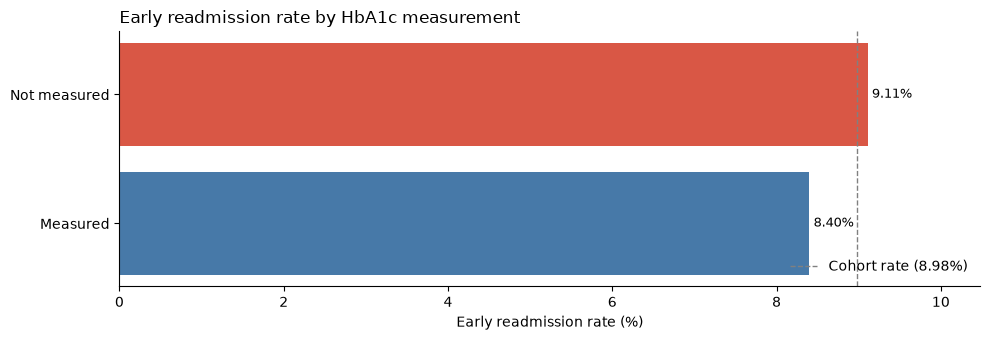

In [39]:
# 7.3 Early readmission by HbA1c measurement
hba1c_plot = hba1c_measured.sort_values("readmission_rate").assign(
    readmission_pct=lambda df: df["readmission_rate"] * 100
)

# Highlight the higher rate
colors = ["#d95745" if val == hba1c_plot["readmission_pct"].max() else "#4779a8"
          for val in hba1c_plot["readmission_pct"]]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(hba1c_plot["hba1c"], hba1c_plot["readmission_pct"], color=colors)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)

ax.axvline(global_rate * 100, color="gray", linestyle="--", linewidth=1,
           label=f"Cohort rate ({global_rate * 100:.2f}%)")
ax.legend(loc="lower right", frameon=False)
ax.set_xlabel("Early readmission rate (%)")
ax.set_title("Early readmission rate by HbA1c measurement", loc="left")
ax.set_xlim(0, hba1c_plot["readmission_pct"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "03_readmission_by_hba1c.png", dpi=150, bbox_inches="tight")
plt.show()

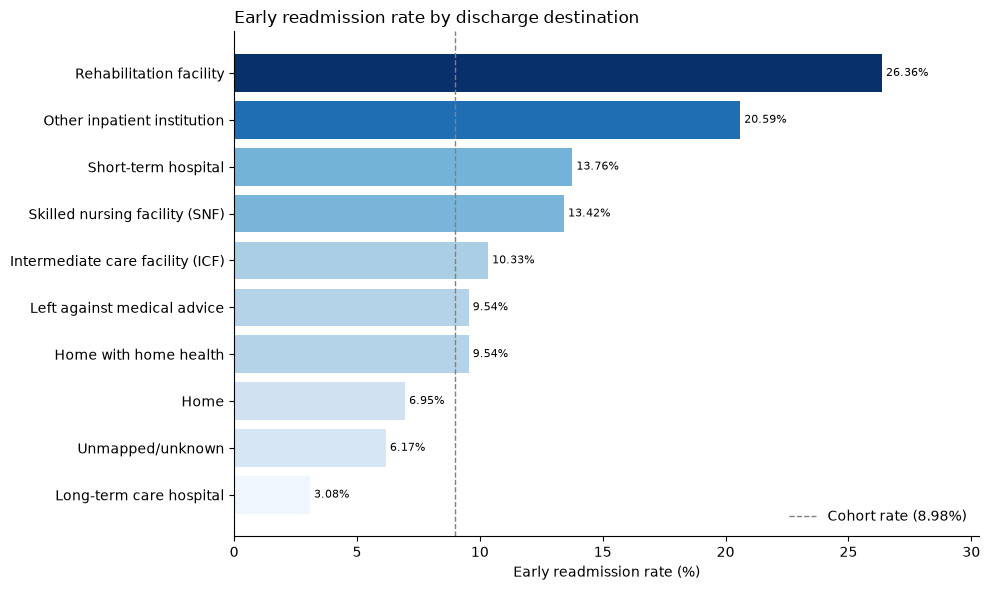

In [40]:
# 7.4 Early readmission by discharge destination (groups with >= 100 patients)
short_names = {
    "Discharged/transferred to another rehab fac including rehab units of a hospital .": "Rehabilitation facility",
    "Discharged/transferred to another type of inpatient care institution": "Other inpatient institution",
    "Discharged/transferred to another short term hospital": "Short-term hospital",
    "Discharged/transferred to SNF": "Skilled nursing facility (SNF)",
    "Discharged/transferred to ICF": "Intermediate care facility (ICF)",
    "Left AMA": "Left against medical advice",
    "Discharged/transferred to home with home health service": "Home with home health",
    "Discharged to home": "Home",
    "Not Mapped": "Unmapped/unknown",
    "Discharged/transferred to a long term care hospital.": "Long-term care hospital",
}
discharge_plot = discharge_readmission.sort_values("readmission_rate").assign(
    discharge_destination=lambda df: df["discharge_destination"].replace(short_names),
    readmission_pct=lambda df: df["readmission_rate"] * 100,
)

norm = plt.Normalize(discharge_plot["readmission_pct"].min() * 0.7, discharge_plot["readmission_pct"].max())
colors = plt.cm.Blues(norm(discharge_plot["readmission_pct"]))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(discharge_plot["discharge_destination"], discharge_plot["readmission_pct"], color=colors)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=8)

ax.axvline(global_rate * 100, color="gray", linestyle="--", linewidth=1,
           label=f"Cohort rate ({global_rate * 100:.2f}%)")
ax.legend(loc="lower right", frameon=False)
ax.set_xlabel("Early readmission rate (%)")
ax.set_title("Early readmission rate by discharge destination", loc="left")
ax.set_xlim(0, discharge_plot["readmission_pct"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "04_readmission_by_discharge_destination.png", dpi=150, bbox_inches="tight")
plt.show()

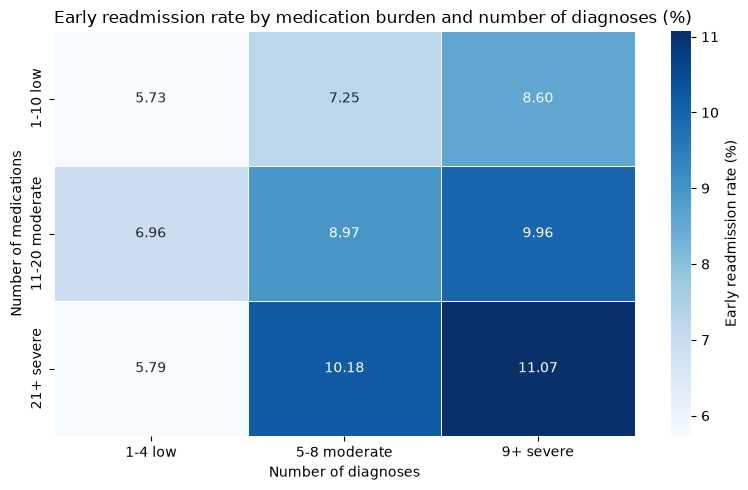

In [41]:
# 7.5 Clinical complexity heatmap (seaborn): medications (rows) x diagnoses (columns)
heatmap_data = complexity_readmission.pivot(
    index="medication_range", columns="diagnosis_range", values="readmission_rate"
) * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "Early readmission rate (%)"}, ax=ax)

ax.set_title("Early readmission rate by medication burden and number of diagnoses (%)", loc="left")
ax.set_xlabel("Number of diagnoses")
ax.set_ylabel("Number of medications")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "05_clinical_complexity_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()